<center>
    <h2>Master 2</h2>
    <h5 style="margin-top: 5px">Sciences de l’Océan, de l’Atmosphère et du Climat</h5>
    <h1>TP - Simulations climatiques</h1>
  <br>
    <strong>Contact:</strong> isaline.bossert@meteo.fr / romain.torres4@gmail.com / gwenael.martin@meteo.fr

</center>


<div style="padding: 1rem; background-color: #d1ecf1; border: 1px solid #bee5eb; border-radius: 4px; margin: 1rem 0;">
  <strong>💡 Instructions</strong> 
    
Ce notebook est à <i>compléter</i> avec vos réponses aux questions posées et à <i>envoyer</i> par mail au plus tard <u>une semaine après la dernière séance de TP</u>. Merci de renommer le notebook pour y incorporer vos noms de famille (ex: TP-Climat-2026-Nom1_Nom2_Nom3.ipynb)
  - une attention particulière doit être donnée aux <b>figures</b> (clareté, titre, axes, légendes, etc..) 
  - les analyses portent sur vos <b>connaissances théoriques</b> en lien avec le cours "Système Climatique" (J. Cattiaux) sont attendues
  - la <b>curiosité scientifique</b> est bien sûre encouragée: même si les questions sont là pour aiguiller le TP, n'hésitez pas à demander des clarifications où d'éventuelles pistes d'analyses supplémentaires ;)
    

⚠️ Lors de la dernière séance, chaque groupe présentera son notebook (sujet + analyses effectuées):
  - durée max de 15 minutes de restitution qui doit être <b>claire</b> et <b>synthétique</b>. Il n'est pas nécessaire de créer un support de présentation particulier.
  - la restitution est suivie d'un <b>tour de questions</b> de la part des élèves puis des enseignantes pour vérifier les notions

<center>
        <h1>Sujet 4: <br>Projection climatique et incertitudes</h1>
  <br>
    <strong>Main topics covered here:</strong>
    <br>
    Projections and uncertainties (c.f. Cours 5)
    <br>
    Internal variability (c.f. Cours 2) 

</center>

## Introduction

Current climate change is primarily driven by the concentrations of greenhouse gases in the atmosphere, which are themselves a result of human activities. Hence, projections of future climate change for the next decades are based on different scenarios of greenhouse gases concentrations, reflecting different socio-economic pathways under several hypitheses (demographic, economic, politics, technologic, etc.). In the last IPCC assessment report [(IPCC AR6)](https://www.ipcc.ch/assessment-report/ar6/), these scenarios are called the _Shared Socioeconomic Pathways_ (SSP) and are classified in five distinct categories from SSP1 to SSP5 ([Fig. 1](#tp4-fig1)). Each category is declined in a suite of scenarios characterized by the end of century radiative forcing (e.g. 2.6, 4.5 and 8.5 W.m$^{-2}$ for SSP1-2.6, SSP2-4.5 and SSP5-8.5, respectively).

Climate models are then used to simulated climate evolution during the 21th century (and even further) for each scenario. Accuracy of these climate projections is function of three different factors ([Fig. 2](#tp4-fig2)):
1. **<span style="color: green;">scenario uncertainty</span>** driven by the choice in SSP scenarios, which alter the concentration of greenhouse gases and anthropic aerosols in the atmopshere resulting in different external focing. 
2. **<span style="color: blue;">model uncertainty</span>**, which quantifies modelling error in simulating the climate responses to external forcing, both from natural (solar radiation, volcanic aerosols, etc.) and anthropic sources.
3. **<span style="color: orange;">internal variability</span>** related to uding chaotic fluctuations of the climate dynamical system when subject to a constant or periodic external forcing (such as the annual cycle).


In this notebook, you will analyze climate projections from a suite of 20 CMIP6 climate models under three SSP (Shared Socio-Economic Pathway): SSP1-2.6, SSP2-4.5, SSP5-8.5. In particular, you will:
  - part 1: SSPs
  - part 2: Uncertainty on the global mean surface temperature
  - part 3: Other variables / regions
  - part 4: RCMs vs GCMs


<br>

<div align="center">
    <div id="tp4-fig1" style="width: 550px; float: left">
        <img src="../figures/IPCC-AR6-SPM-Fig3.png" alt="drawing" width="500"/>
    </div>
    <div id="tp4-fig2" style="width: 300px; float right">
        <br><br><br><br>
        <img src="../figures/Hawkins_and_Sutton-2009-Fig4.png" alt="drawing" width="400"/>
    </div>
    <br>
    <div>
    <div style="width: 550px; float: left">
    <b>Fig. 1. </b>Global surface temperature changes relative to 1850-1900 for five different shared socioeconomic pathways (SSPs). Taken from <a href="https://www.ipcc.ch/report/ar6/wg2/figures/summary-for-policymakers/">IPCC AR6 - SPM</a>.
    </div>
    <div style="width: 300px; float right">
    <b>Fig. 2. </b>The fraction of total variance in decadal mean surface air temperature predictions explained by the three components of total uncertainty for the global mean. Green regions represent scenario uncertainty, blue regions represent model uncertainty, and orange regions represent the internal variability component. Taken from <a href="https://doi.org/10.1175/2009BAMS2607.1">Hawkins and Sutton (2009)</a>.
    </div>
    </div>
</div>

<br><br><br><br>

## Load Python modules and simulation outputs

Along this notebook, Python codes are used to analyse model outputs.
You first need to import and load required modules:

In [1]:
# manipulate file and data
import os
import numpy  as np
import pandas as pd
import xarray as xr

# plotting
import matplotlib
import matplotlib.pyplot as plt

The code below loads results from 20 CMIP6 climate models for scenarios SSP1-2.6, SSP2-4.5 and SSP5-8.5.

In [17]:
# initialize empty dict to store variables
ssp126 = dict()
ssp245 = dict()
ssp585 = dict()


# load 20 models in csv (.asc) files using pandas and convert into xarray.Dataset
df = pd.read_csv('../data/'+"T_Glo_ANN_ssp126.asc", sep=" ")-273.15
ssp126['ts'] = xr.DataArray(data=df.values,
                            dims=('year', 'model'),
                            coords={'year': np.array(df.index), 'model': np.array(df.columns)}
                           )

df = pd.read_csv('../data/'+"T_Glo_ANN_ssp245.asc", sep=" ")-273.15
ssp245['ts'] = xr.DataArray(data=df.values,
                            dims=('year', 'model'),
                            coords={'year': np.array(df.index), 'model': np.array(df.columns)}
                           )

df = pd.read_csv('../data/'+"T_Glo_ANN_ssp585.asc", sep=" ")-273.15
ssp585['ts'] = xr.DataArray(data=df.values,
                            dims=('year', 'model'),
                            coords={'year': np.array(df.index), 'model': np.array(df.columns)}
                           )

# load some model outputs with precip in csv (.asc)
df = pd.read_csv('../data/'+"Pr_Glo_ANN_ssp126.asc", sep=" ", index_col=0)
ssp126['pr'] = xr.DataArray(data=df.values,
                            dims=('year', 'model'),
                            coords={'year': np.array(df.index), 'model': np.array(df.columns)}
                           )

df = pd.read_csv('../data/'+"Pr_Glo_ANN_ssp245.asc", sep=" ", index_col=0)
ssp245['pr'] = xr.DataArray(data=df.values,
                            dims=('year', 'model'),
                            coords={'year': np.array(df.index), 'model': np.array(df.columns)}
                           )

df = pd.read_csv('../data/'+"Pr_Glo_ANN_ssp585.asc", sep=" ", index_col=0)
ssp585['pr'] = xr.DataArray(data=df.values,
                            dims=('year', 'model'),
                            coords={'year': np.array(df.index), 'model': np.array(df.columns)}
                           )

# add CO2 emissions for each scenario
ar = np.loadtxt('../data/CO2/SSPs-CO2_emissions.csv', skiprows=1)
ssp126['co2_emissions'] = xr.DataArray(data=ar[:,1], dims=('year'), coords={'year': ar[:,0]})
ssp245['co2_emissions'] = xr.DataArray(data=ar[:,2], dims=('year'), coords={'year': ar[:,0]})
ssp585['co2_emissions'] = xr.DataArray(data=ar[:,3], dims=('year'), coords={'year': ar[:,0]})

print("Models loaded: \n", list(ssp126['ts']['model'].data))

Models loaded: 
 ['ACCESS-CM2', 'MPI-ESM1-2-HR', 'UKESM1-0-LL', 'ACCESS-ESM1-5', 'CESM2-WACCM', 'INM-CM4-8', 'MPI-ESM1-2-LR', 'FGOALS-f3-L', 'INM-CM5-0', 'MRI-ESM2-0', 'CNRM-CM6-1-HR', 'IPSL-CM6A-LR', 'NorESM2-LM', 'CNRM-CM6-1', 'GISS-E2-1-G', 'MIROC6', 'NorESM2-MM', 'CNRM-ESM2-1', 'HadGEM3-GC31-LL', 'MIROC-ES2L']


Here, the global mean surface temperature (GMST) is available in three python dictionnaries `ssp126`, `ssp245` and `ssp585`.
You can access to the data, by using the variable name:

```python
    ssp126['ts']            # this return an xarray.DataArray object
    ssp126['ts'].data       # this return an numpy.array object
    ssp126['ts']['year']    # this return the 'year' coordinate for the variable 'ts'
```

In addition, we loaded CO$_2$ emissions combined from historical inventory and SSP scenarios:

```python
    ssp126['co2_emissions']  # this return an xarray.DataArray object
```

<a id="section-1"></a>
## 1. Shared Socioeconomics Pathways 

We first take a look into the trajectory of the three selected Shared Socioeconomic Pathways (SSPs): SSP1-2.6, SSP2-4.5 and SSP5-8.5. 

#### Question 1

* _Plot the time-series for CO$_2$ emissions in the three SSPs._
* _What do you see ?_


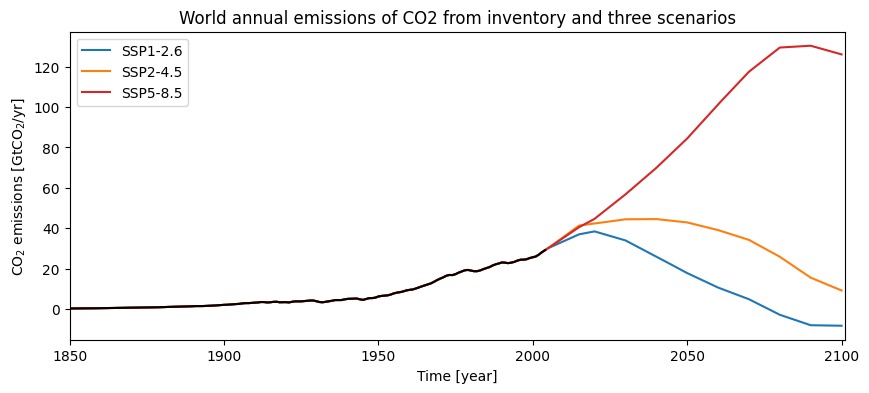

In [9]:
# plot
fig, ax = plt.subplots(1,1, figsize=(10, 4))

ax.plot( ssp126['co2_emissions']['year'], 1e-9*ssp126['co2_emissions'], label='SSP1-2.6', c='tab:blue')
ax.plot( ssp245['co2_emissions']['year'], 1e-9*ssp245['co2_emissions'], label='SSP2-4.5', c='tab:orange')
ax.plot( ssp585['co2_emissions']['year'], 1e-9*ssp585['co2_emissions'], label='SSP5-8.5', c='tab:red')
ax.plot( ssp126['co2_emissions']['year'][:155], 1e-9*ssp126['co2_emissions'][:155],       c='k')

# axe properties
ax.set_xlabel('Time [year]')
ax.set_ylabel(r'CO$_2$ emissions [GtCO$_2$/yr]')

ax.set_xlim((1850, 2101))

ax.legend()

_ = ax.set_title("World annual emissions of CO2 from inventory and three scenarios")

<font color="blue">

- emissions have increased exponentially since 1950
- the 3 scenarios show different trajectory; it is worthnoting that SSP1-2.6 requires negative emissions to reach a low level of radiative forcing in 2100.
- Covid pandemic not seen here, seens the inventory ends in 2005
    
</font>

#### Question 2

* _Plot the time-series for global mean surface temperature (GMST) in the three SSPs._

__Help:__ remember that 20 models are used, all of them having a different pre-industrial global mean surface temperature level. It is therefore more convenient to work with anomalies of GMST $\Delta T_s$.

To avoid too much lines in your graph you can either split in several plots or use the functions [xarray.mean](https://docs.xarray.dev/en/stable/generated/xarray.DataArray.mean.html) and [xarray.std](https://docs.xarray.dev/en/stable/generated/xarray.DataArray.std.html) to characterize each scenario.

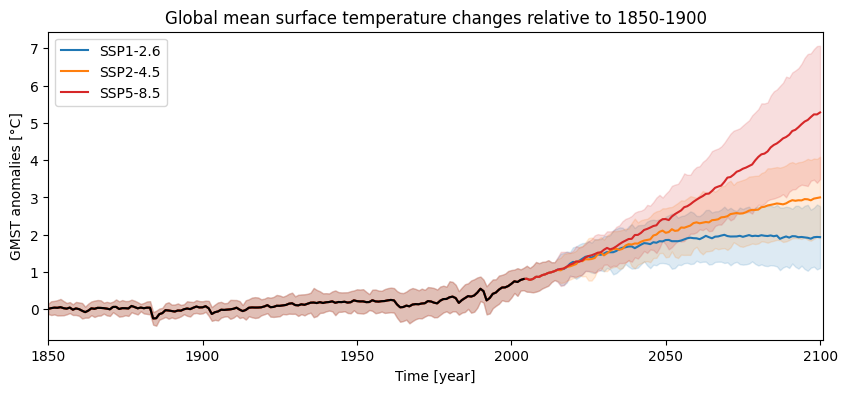

In [28]:
# plot
fig, ax = plt.subplots(1,1, figsize=(10, 4))

# compute GMST anomalies
ssp126['tsa'] = (ssp126['ts'] - ssp126['ts'].isel({'year': slice(0, 50)}).mean('year'))
ssp245['tsa'] = (ssp245['ts'] - ssp245['ts'].isel({'year': slice(0, 50)}).mean('year'))
ssp585['tsa'] = (ssp585['ts'] - ssp585['ts'].isel({'year': slice(0, 50)}).mean('year'))

# get mean and std for each scenario
mean126 = ssp126['tsa'].mean('model')
std126  = ssp126['tsa'].std('model')

mean245 = ssp245['tsa'].mean('model')
std245  = ssp245['tsa'].std('model')

mean585 = ssp585['tsa'].mean('model')
std585  = ssp585['tsa'].std('model')

# plot multi-model mean
ax.plot( ssp126['ts']['year'], mean126,         label='SSP1-2.6', lw=1.5, c='tab:blue')
ax.plot( ssp245['ts']['year'], mean245,         label='SSP2-4.5', lw=1.5, c='tab:orange')
ax.plot( ssp585['ts']['year'], mean585,         label='SSP5-8.5', lw=1.5, c='tab:red')
ax.plot( ssp126['ts']['year'][:155], ssp126['tsa'].mean('model')[:155],   c='k')

# plot range
ax.fill_between( ssp126['ts']['year'], mean126+1.64*std126, mean126-1.64*std126, color='tab:blue',   alpha=0.15)
ax.fill_between( ssp245['ts']['year'], mean245+1.64*std245, mean245-1.64*std245, color='tab:orange', alpha=0.15)
ax.fill_between( ssp585['ts']['year'], mean585+1.64*std585, mean585-1.64*std585, color='tab:red',    alpha=0.15)

# axe properties
ax.set_xlabel('Time [year]')
ax.set_ylabel(r'GMST anomalies [°C]')

ax.set_xlim((1850, 2101))

ax.legend(loc=2)

_ = ax.set_title("Global mean surface temperature changes relative to 1850-1900")

<font color="blue">

- Discuss how the spread changes with time and with scenarios; why ?
    
- There is a correlation between warming and CO$_2$ emiisions
    
- $\Delta T_s$ in SSP2-4.5 still increases during all the 21th century even if CO$_2$ emissions decreases from year 2040.
    
- in the historical periods, there are some very rapid changes in temperature due to natural volcanic aerosols (external forcing) that tends to cool the climate
    
- scenario uncertainty is evident from 2050 to 2100; model uncertainty + internal variavility are shown with the 1.64$\sigma$ spread
    
</font>

#### Question 3 

* _Combine the two previous metrics by plotting temperature change against cummulative CO$_2$ emissions._
* _How do you intepret the figure ?_

__Help:__ you can compute cummulative emissions with the [xarray.cumsum](https://docs.xarray.dev/en/stable/generated/xarray.DataArray.cumsum.html) function.

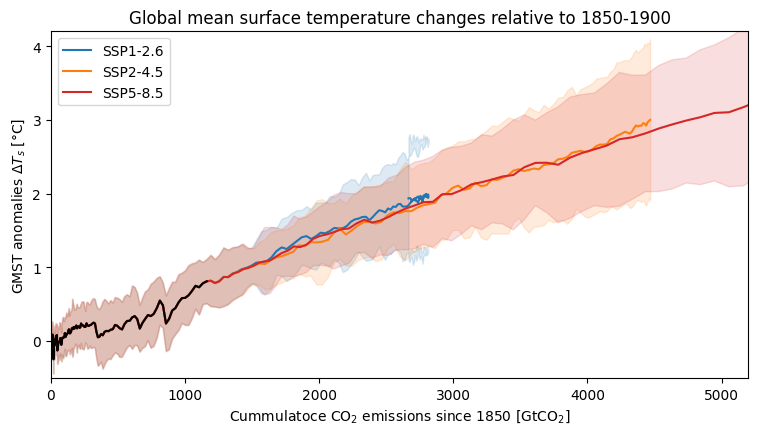

In [11]:
# plot
fig, ax = plt.subplots(1,1, figsize=(9, 4.5))

# get cummulative sum of CO2 emissions
cum_co2_ssp126 = 1e-9*ssp126['co2_emissions'].cumsum('year')
cum_co2_ssp245 = 1e-9*ssp245['co2_emissions'].cumsum('year')
cum_co2_ssp585 = 1e-9*ssp585['co2_emissions'].cumsum('year')

# plot multi-model mean against cummulative CO2
ax.plot( cum_co2_ssp126, mean126,         label='SSP1-2.6', lw=1.5, c='tab:blue')
ax.plot( cum_co2_ssp245, mean245,         label='SSP2-4.5', lw=1.5, c='tab:orange')
ax.plot( cum_co2_ssp585, mean585,         label='SSP5-8.5', lw=1.5, c='tab:red')
ax.plot( cum_co2_ssp126[:155], ssp126['tsa'].mean('model')[:155],   c='k')

# plot range
ax.fill_between( cum_co2_ssp126, mean126+1.64*std126, mean126-1.64*std126, color='tab:blue',   alpha=0.15)
ax.fill_between( cum_co2_ssp245, mean245+1.64*std245, mean245-1.64*std245, color='tab:orange', alpha=0.15)
ax.fill_between( cum_co2_ssp585, mean585+1.64*std585, mean585-1.64*std585, color='tab:red',    alpha=0.15)

# axe properties
ax.set_xlabel('Cummulatoce CO$_2$ emissions since 1850 [GtCO$_2$]')
ax.set_ylabel(r'GMST anomalies $\Delta T_s$ [°C]')

ax.set_xlim((0, 5200))
ax.set_ylim((-0.5, 4.2))

ax.legend(loc=2)

_ = ax.set_title("Global mean surface temperature changes relative to 1850-1900")

<font color="blue">

- we retrieve the well known quasi linear relationship between $\Delta T_s$ and CO$_2$ emissions 
    
</font>

#### Question 4

* _Plot the time-series for global averaged precipitation in the three SSPs._
* _Can you find a correlation with another variable ? Why ?_

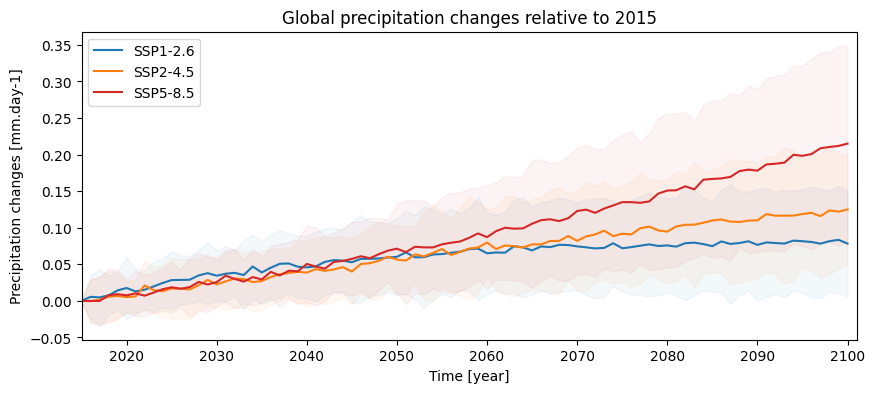

In [63]:
# plot
fig, ax = plt.subplots(1,1, figsize=(10, 4))

# compute precipitation anomalies
ssp126['pra'] = (ssp126['pr'] - ssp126['pr'].isel({'year': 0}))
ssp245['pra'] = (ssp245['pr'] - ssp245['pr'].isel({'year': 0}))
ssp585['pra'] = (ssp585['pr'] - ssp585['pr'].isel({'year': 0}))

# get mean and std for each scenario
mean126_pr = ssp126['pra'].mean('model')
std126_pr  = ssp126['pra'].std('model')

mean245_pr = ssp245['pra'].mean('model')
std245_pr  = ssp245['pra'].std('model')

mean585_pr = ssp585['pra'].mean('model')
std585_pr  = ssp585['pra'].std('model')

# plot multi-model mean
ax.plot( ssp126['pr']['year'], mean126_pr,         label='SSP1-2.6', lw=1.5, c='tab:blue')
ax.plot( ssp245['pr']['year'], mean245_pr,         label='SSP2-4.5', lw=1.5, c='tab:orange')
ax.plot( ssp585['pr']['year'], mean585_pr,         label='SSP5-8.5', lw=1.5, c='tab:red')

# plot range
ax.fill_between( ssp126['pr']['year'], mean126_pr+1.64*std126_pr, mean126_pr-1.64*std126_pr, 
                                                                    color='tab:blue',   alpha=0.05)
ax.fill_between( ssp245['pr']['year'], mean245_pr+1.64*std245_pr, mean245_pr-1.64*std245_pr, 
                                                                    color='tab:orange', alpha=0.05)
ax.fill_between( ssp585['pr']['year'], mean585_pr+1.64*std585_pr, mean585_pr-1.64*std585_pr, 
                                                                    color='tab:red',    alpha=0.05)

# axe properties
ax.set_xlabel('Time [year]')
ax.set_ylabel(r'Precipitation changes [mm.day-1]')

ax.set_xlim((2015, 2101))

ax.legend(loc=2)

_ = ax.set_title("Global precipitation changes relative to 2015")

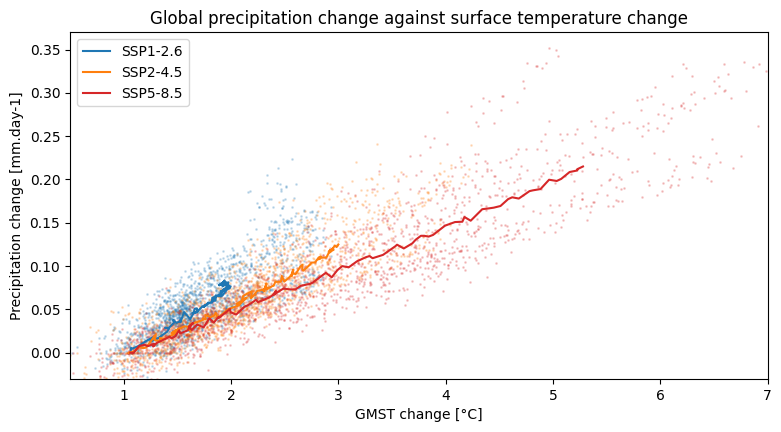

In [61]:
# plot
fig, ax = plt.subplots(1,1, figsize=(9, 4.5))

# compute precipitation anomalies
ssp126['pra'] = (ssp126['pr'] - ssp126['pr'].isel({'year': 0}))
ssp245['pra'] = (ssp245['pr'] - ssp245['pr'].isel({'year': 0}))
ssp585['pra'] = (ssp585['pr'] - ssp585['pr'].isel({'year': 0}))

# get mean and std for each scenario
mean126_pr = ssp126['pra'].mean('model')
std126_pr  = ssp126['pra'].std('model')

mean245_pr = ssp245['pra'].mean('model')
std245_pr  = ssp245['pra'].std('model')

mean585_pr = ssp585['pra'].mean('model')
std585_pr  = ssp585['pra'].std('model')

# plot multi-model mean
ax.plot( mean126.sel({'year': slice(2015,2101)}), mean126_pr, lw=1.5, label='SSP1-2.6', c='tab:blue')
ax.plot( mean245.sel({'year': slice(2015,2101)}), mean245_pr, lw=1.5, label='SSP2-4.5', c='tab:orange')
ax.plot( mean585.sel({'year': slice(2015,2101)}), mean585_pr, lw=1.5, label='SSP5-8.5', c='tab:red')

ax.scatter( ssp126['tsa'].sel({'year': slice(2015,2101)}), ssp126['pra'], s=1, alpha=0.2, c='tab:blue')
ax.scatter( ssp245['tsa'].sel({'year': slice(2015,2101)}), ssp245['pra'], s=1, alpha=0.2, c='tab:orange')
ax.scatter( ssp585['tsa'].sel({'year': slice(2015,2101)}), ssp585['pra'], s=1, alpha=0.2, c='tab:red')


# axe properties
ax.set_xlabel('GMST change [°C]')
ax.set_ylabel(r'Precipitation change [mm.day-1]')

ax.set_xlim((0.5, 7))
ax.set_ylim((-0.03, 0.37))

ax.legend(loc=2)

_ = ax.set_title("Global precipitation change against surface temperature change")

<font color="blue">

- **Modification of the global hydrological cycle.**

  - CLausius-Clapeyron: warmer atmosphere = water vapour in its constitution; in turn this leads to more evaporation/precipitation (intensification of the hydrological cycle)
    
  - the relation is linear with $\Delta T_s$ (and thus with cummulative CO$_2$)
    
</font>

<a id="section-2"></a>
## 2. Climate sensitivity


In the previous section, we have estimate the energy imbalance within the CNRM-CM6-1 climate model and how the simulated climate have changed (its surface temperature $\Delta T$) in response to a fixed radiative forcing.

Here, we will use the concept of climate sensitivity, also called Equilibrium Climate Sensitivity (ECS), to quantify the magnitude of the response. The ECS is a useful metric to compare climate models or different forcing experiments (e.g. aerosols, greenhouse gases, solar variability).

We first recall that the Earth surface temperature change ($\Delta T$) can be linearized and written as:
$$ \Delta R = F - \lambda \Delta T$$
where $\Delta R$ is the net resulting energy flux (at the top of the atmosphere) and $F$ the radiative forcing (i.e. a perturbation from the energy budget at the equilibrium). 

The surface temperature will change until a new equilibrium is reached when $\Delta R = 0$, leading to:
$$ \left(\Delta T\right)_\text{eq} = F / |\lambda|$$

Here, the parameter $\lambda$ is called the climate sensitivity parameter ($<0$) in W.m$^{-2}$.K$^{-1}$. It indicates the strength of the climate system response. It can be computed from a the new equilibrium $\lambda = -F / \left(\Delta T\right)_\text{eq}$, or (if the equilibrium has not been reached) by linear regression of the function $\Delta R = f(\Delta T)$ as proposed by [Gregory et al. (2004)](https://doi.org/10.1029/2003GL018747).

The climate sensitivity (ECS) is the surface temperature change required to reach the equilibrium $\left(\Delta T\right)_\text{eq}$ in °C.

#### Question 6:

* _Plot the transcient response of the abrupt-4xCO2 experiment in the $\{\Delta T, \Delta R\}$_
* _Compute the ECS and the climate sensitivity for CNRM-CM6-1_

__Help:__ you can use `plt.scatter` for plotting results.

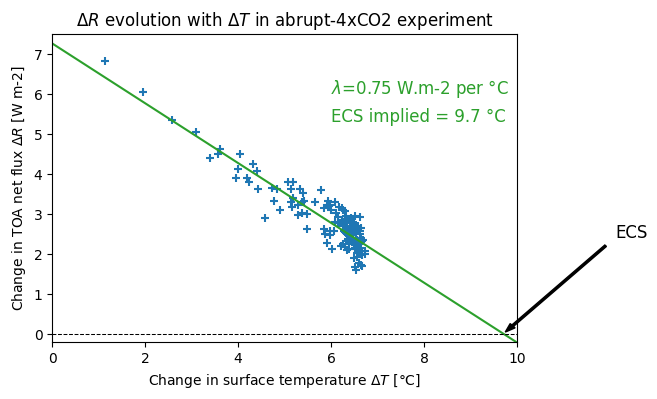

In [8]:
# plot
fig, ax = plt.subplots(1,1, figsize=(6, 4))

ax.scatter( dT, dR, marker='+', c='tab:blue')

# compute linear trend (lambda) and ECS
x         = np.vstack([dT, np.ones(len(dT))]).T
coeff, R0 = np.linalg.lstsq(x, dR, rcond=-1)[0]

ecs       = -R0 / coeff  # dT = -dR/lambda

# plot trend
ax.plot( np.linspace(0, 10, 100), coeff * np.linspace(0, 10, 100) + R0, ls='-', c='tab:green')

# add ECS on plot
ax.arrow(ecs+2.2, 2.2, -2, -2, width=0.05, color='k', clip_on=False)
ax.text(ecs+2.4, 2.4, "ECS", fontsize=12,  c='k')

ax.text(6, 6,   r"$\lambda$={:.2f} W.m-2 per °C".format(-coeff), fontsize=12,  c='tab:green')
ax.text(6, 5.3, r"ECS implied = {:.1f} °C".format(ecs),           fontsize=12,  c='tab:green')

# plot y=0 line
ax.plot( [0, 10], [0, 0], ls='--', lw=0.75, c='k')

# axe properties
ax.set_xlim((0, 10))
ax.set_ylim((-0.2, 7.5))
ax.set_xlabel(r'Change in surface temperature $\Delta T$ [°C]')
ax.set_ylabel(r'Change in TOA net flux $\Delta R$ [W m-2]')

_ = ax.set_title(r"$\Delta R$ evolution with $\Delta T$ in abrupt-4xCO2 experiment")

#### Question 7

* _Based on the previous computation of the ECS (using the linear approximation), do you think that another method could out-perform a linear fit ? What about the choice of a constant $\lambda$ ?_


__Help:__ you can try to plot ECS and the feedback parameters for different timescales (e.g. decadal, centenial).

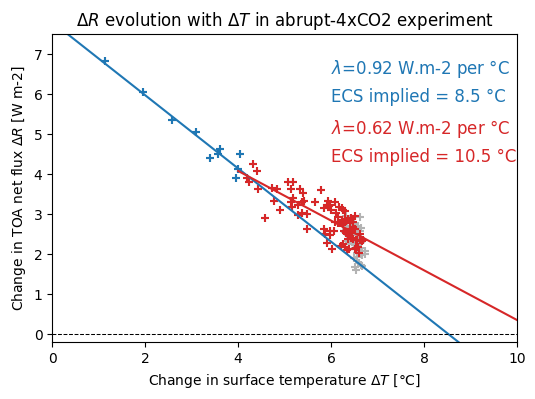

In [9]:
# plot
fig, ax = plt.subplots(1,1, figsize=(6, 4))

ax.scatter( dT, dR, marker='+', color=np.array([.7,.7,.7]))

# compute the method for the 0-10 years period
yi, yf = 0, 10

ax.scatter( dT[yi:yf], dR[yi:yf], marker='+', c='tab:blue')

x         = np.vstack([dT[yi:yf], np.ones(len(dT[yi:yf]))]).T
coeff, R0 = np.linalg.lstsq(x, dR[yi:yf], rcond=-1)[0]
ecs       = -R0 / coeff  # dT = -dR/lambda

ax.plot( np.linspace(0, 10, 100), coeff * np.linspace(0, 10, 100) + R0, ls='-', c='tab:blue')

ax.text(6, 6.5,   r"$\lambda$={:.2f} W.m-2 per °C".format(-coeff), fontsize=12,  c='tab:blue')
ax.text(6, 5.8, r"ECS implied = {:.1f} °C".format(ecs),          fontsize=12,  c='tab:blue')

# compute the method for the 10-100 years period
yi, yf = 10, 100

ax.scatter( dT[yi:yf], dR[yi:yf], marker='+', c='tab:red')

x         = np.vstack([dT[yi:yf], np.ones(len(dT[yi:yf]))]).T
coeff, R0 = np.linalg.lstsq(x, dR[yi:yf], rcond=-1)[0]
ecs       = -R0 / coeff  # dT = -dR/lambda

ax.plot( np.linspace(4, 10, 100), coeff * np.linspace(4, 10, 100) + R0, ls='-', c='tab:red')

ax.text(6, 5, r"$\lambda$={:.2f} W.m-2 per °C".format(-coeff), fontsize=12,  c='tab:red')
ax.text(6, 4.3, r"ECS implied = {:.1f} °C".format(ecs),          fontsize=12,  c='tab:red')

# plot y=0 line
ax.plot( [0, 10], [0, 0], ls='--', lw=0.75, c='k')

# axe properties
ax.set_xlim((0, 10))
ax.set_ylim((-0.2, 7.5))
ax.set_xlabel(r'Change in surface temperature $\Delta T$ [°C]')
ax.set_ylabel(r'Change in TOA net flux $\Delta R$ [W m-2]')

_ = ax.set_title(r"$\Delta R$ evolution with $\Delta T$ in abrupt-4xCO2 experiment")

<font color="blue">

Coupled atmosphere-ocean models, take millennia to reach a new steady state, making analysis of the climate sensitivity difficult.
Indeed, ocean and atmopshere circulations have changed due to external forcings while non-linear feedbacks can arise at different time-scales.   
    
In this figure, we have computed the climate sensitivity (ECS) and the feedback parameter $\lambda$ for two different time scale: decadal (0-10 years) and centenial (10-100 years). We found that the ECS is greater (+2.0°C) at centenial timescale than decadal. Is that closer to what longer simulation gives ? 
Howevern the climate feedback parameter is reduced at longer time scales, expressing that the climate response is stronger at the beginning (to adapt to the forcing) and then tends to slow down due to long-term equilibration within the system (e.g. deep ocean circulation, air-sea-ice interactions, etc.)    

</font>

#### Question 8

* _Confirm your hypothesis and extrapolation results by using longer 4xCO2 experiments_

__Help__: you can load the yearly-averaged data for longer simulations with the following lines :

```python
# initialize empty dict to store variables
piCtrl_cnrm = dict()
abrupt_cnrm = dict()

# load netCDF (.nc) files using xarray
for f in os.listdir("../data/CNRM-CM6-1"):
    var   = f.split('_')[0]
    expe  = f.split('_')[3]
    
    # select only CNRM-CM6-1 model
    if expe == 'piControl':
        ds = xr.load_dataset(os.path.join("../data/CNRM-CM6-1", f), use_cftime=True)
        
        piCtrl_cnrm[var]      = ds[list(ds.variables)[-1]]
        piCtrl_cnrm[var].name = var
        
    elif expe == 'abrupt-4xCO2':
        ds = xr.load_dataset(os.path.join("../data/CNRM-CM6-1", f), use_cftime=True)

        abrupt_cnrm[var]      = ds[list(ds.variables)[-1]]
        abrupt_cnrm[var].name = var
```

In [10]:
# initialize empty dict to store variables
piCtrl_cnrm = dict()
abrupt_cnrm = dict()

# load netCDF (.nc) files using xarray
for f in os.listdir("../data/CNRM-CM6-1"):
    var   = f.split('_')[0]
    expe  = f.split('_')[3]

    # select only CNRM-CM6-1 model
    if expe == 'piControl':
        ds = xr.load_dataset(os.path.join("../data/CNRM-CM6-1", f), use_cftime=True)

        piCtrl_cnrm[var]      = ds[list(ds.variables)[-1]]
        piCtrl_cnrm[var].name = var

    elif expe == 'abrupt-4xCO2':
        ds = xr.load_dataset(os.path.join("../data/CNRM-CM6-1", f), use_cftime=True)

        abrupt_cnrm[var]      = ds[list(ds.variables)[-1]]
        abrupt_cnrm[var].name = var

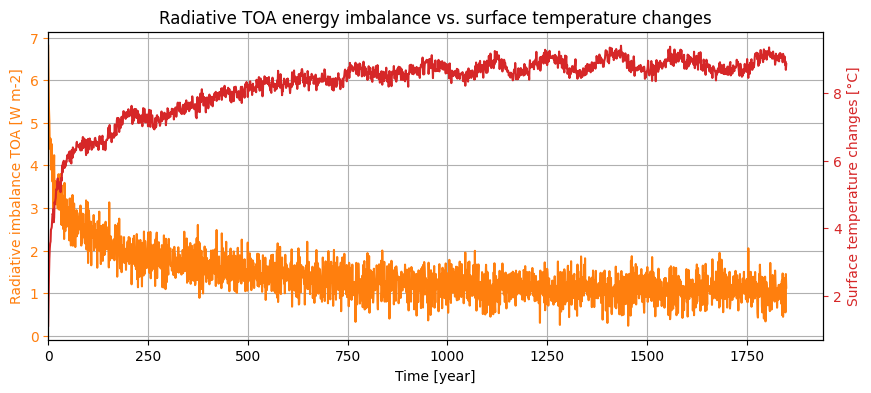

In [11]:
dR_piCtrl_cnrm = piCtrl_cnrm['rsdt'] - piCtrl_cnrm['rsut'] - piCtrl_cnrm['rlut']
dR_abrupt_cnrm = abrupt_cnrm['rsdt'] - abrupt_cnrm['rsut'] - abrupt_cnrm['rlut']

dT_long      = (abrupt_cnrm['ts'] - piCtrl_cnrm['ts'])
dR_long      =  dR_abrupt_cnrm    - dR_piCtrl_cnrm

# plot
fig, ax = plt.subplots(1,1, figsize=(10, 4))

# dR
ax.plot( np.arange(len(dR_long['year'])), dR_long, c='tab:orange')

# dT
ax2 = ax.twinx()
ax2.plot( np.arange(len(dT_long['year'])), dT_long, c='tab:red')

ax.grid(True)
ax.set_xlim((0, None))
ax.set_xlabel('Time [year]')
ax.set_ylabel('Radiative imbalance TOA [W m-2]',   color='tab:orange')
ax2.set_ylabel('Surface temperature changes [°C]', color='tab:red')

ax.tick_params(axis='y' , colors='tab:orange')
ax2.tick_params(axis='y', colors='tab:red')


_ = ax.set_title("Radiative TOA energy imbalance vs. surface temperature changes")

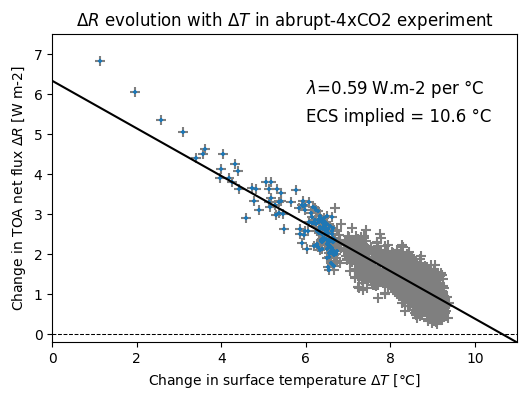

In [12]:
# plot
fig, ax = plt.subplots(1,1, figsize=(6, 4))

ax.scatter( dT_long, dR_long, marker='+', s=50, c='tab:grey')
ax.scatter( dT, dR,           marker='+', s=5, c='tab:blue')

# compute linear trend (lambda) and ECS
x         = np.vstack([dT_long, np.ones(len(dT_long))]).T
coef2, R0 = np.linalg.lstsq(x, dR_long, rcond=-1)[0]

ecs_long  = -R0 / coef2  # dT = -dR/lambda

# plot trend
ax.plot( np.linspace(0, 11, 100), coef2 * np.linspace(0, 11, 100) + R0, ls='-', c='k')

# add ECS on plot
ax.text(6, 6,   r"$\lambda$={:.2f} W.m-2 per °C".format(-coef2), fontsize=12,  c='k')
ax.text(6, 5.3, r"ECS implied = {:.1f} °C".format(ecs_long),     fontsize=12,  c='k')

# plot y=0 line
ax.plot( [0, 11], [0, 0], ls='--', lw=0.75, c='k')

# axe properties
ax.set_xlim((0, 11))
ax.set_ylim((-0.2, 7.5))
ax.set_xlabel(r'Change in surface temperature $\Delta T$ [°C]')
ax.set_ylabel(r'Change in TOA net flux $\Delta R$ [W m-2]')

_ = ax.set_title(r"$\Delta R$ evolution with $\Delta T$ in abrupt-4xCO2 experiment")

<font color="blue">
   
In the first figure, we showed the time series of both $\Delta R$ and $\Delta T$ for longer runs of CNRM-CM6-1.
Compared to the original _abrupt-4xCO2_ experiment of 150 years, the climate reaches a warmer global surface temperature o +2°C and get a lower imbalance (two times weaker). It is important to note that $\Delta R$ is greater than zero enven after 1750 years of simulation, showing that the climate model has not reach an equilibrium in a theoretical sense. However, the imbalance seems quite stable after ~1500 years. Furthermore, we have shown in Question 3 that a residual imbalance exists in CNRM-CM6-1 even in the _piControl_ experiment. This seems to indicate that the model has an equilibrium state with $(\Delta R)_{eq} \neq 0$, with $(\Delta R)_{eq}$ is dependant of the climate state; in other words it is different for _piControl_ and _abrupt-4xCO2_.
    
In the second figure, we have plotted again the climate response in the ($\Delta R$, $\Delta T$) diagram but for the longer runs. The new ECS and feedback parameter are close to the one computed on centenial timescales (c.f. Question 7).

</font>

<a id="section-3"></a>
## 3. Mechanisms and climate feedbacks


In the previous sections, we have analyzed the Earth energy balance and showed how the climate respond to an external CO$_2$ forcing. We will now try to understand the mechanisms that drive this response.

Climate feedbacks are internal mechanisms which can alter the response to an initial perturbation. We call a _positive_ and _negative_ feedback when the mechanism tends to amply or diminish the response, respectively.

#### Question 9

* _Recall relatively known radiative feedbacks and try to relate them to the terms involved in the Earth energy balance ([section 1](#section-1))_    

<font color="blue">

From the lectures (Cours 3) of J. Cattiaux, there are few main feedbacks that arise from a CO$_2$ forcing:
    
  - __Water vapour feedback__ that arise because a warmer air has a greater capacity to contain vapour before being saturated. Since the water vapour is a greenhouse gas, the feedback is __positive__. This mechanism is not directly related to a energy flux term but itstead increase the external forcing term $F$ in the energy balance.
    $$ F_{CO_2} \rightarrow T_s^\nearrow \rightarrow F_{GHG}^\nearrow \rightarrow T_s^\nearrow $$
    
    
  - __The lapse rate feedback__ is due because the troposphere does not warm similarly in all the air column, resulting in a change of the emission temperature $T_e$ and thus, a change in the longwave upward energy flux ($\sigma T_e^4$). THis could be __positive or negative__ (in fact this depend on the geography).
    $$ F_{CO_2} \rightarrow T_s^\nearrow \rightarrow \Delta \partial_z T \rightarrow \Delta T_e \rightarrow \Delta T_s $$

    
  - __Albedo feedback__ that arise in a change of the albedo parameter $\alpha$ (i.e. the capacity of the system to reflect solar radiation) through the term $\alpha S_0/4$. This can reflect either a change in the surface albedo or a change in clouds reflection. Surface albedo is overall __positive__ but sign of the cloud feedbacks in still uncertain.
    $$ F_{CO_2} \rightarrow T_s^\nearrow \rightarrow \alpha^\searrow \rightarrow SW_\mathrm{up}^\searrow \rightarrow T_s^\nearrow $$
    
    
   - __Clouds__ can also alter the atmosphere transmissivity $\tau_a$, hence changing the longwave emission term \sigma T_e^4. However, large uncertainty arise from clouds in climate models so that sign of the feedback remains unknown.
    $$ F_{CO_2} \rightarrow T_s^\nearrow \rightarrow \Delta \tau_a \rightarrow \Delta \sigma T_e \rightarrow \Delta T_s $$
</font>

#### Question 10

We will now focus on the effect of the clouds in the _abrupt-4xCO2_ experiment.

* _Using the clear-sky variables (e.g. rlutcs) propose a figure illustrating clouds effect._    

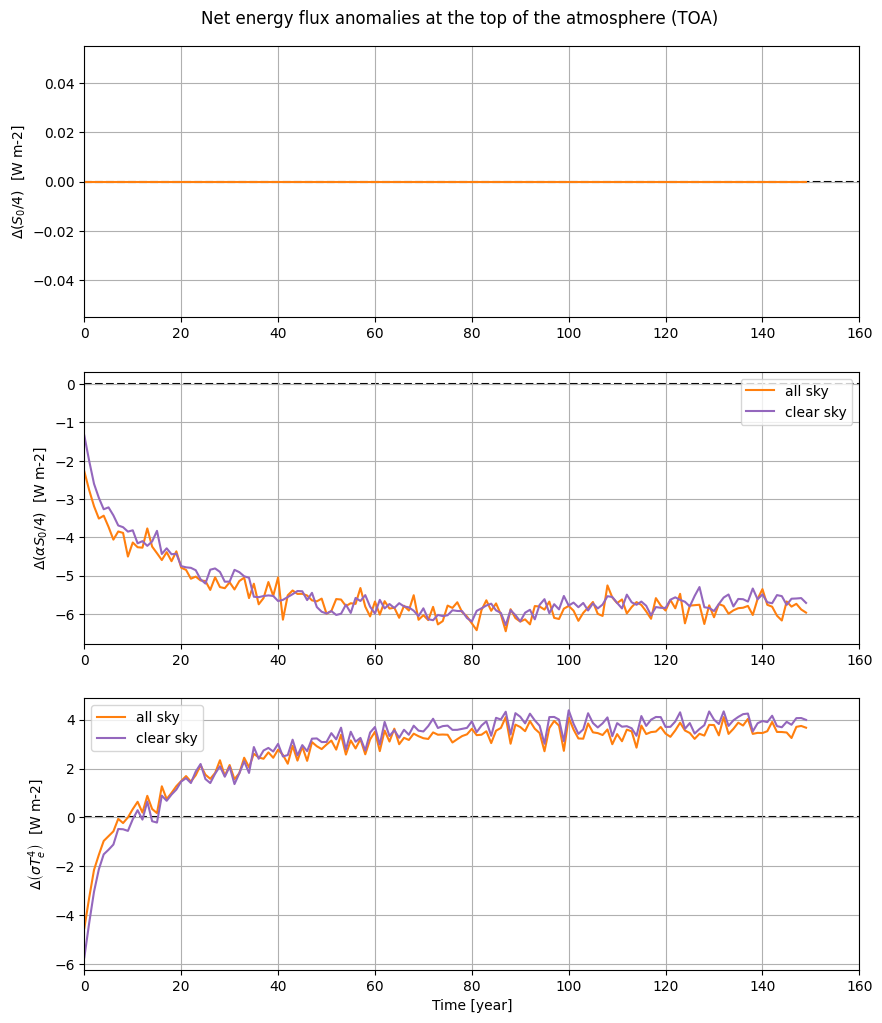

In [13]:
# plot temperature and energy anomalies
fig, axes = plt.subplots(3,1, figsize=(10, 12))

dRLUT     = (abrupt['rlut'] - piCtrl['rlut']).groupby('time.year').mean()
dRSUT     = (abrupt['rsut'] - piCtrl['rsut']).groupby('time.year').mean()
dRSDT     = (abrupt['rsdt'] - piCtrl['rsdt']).groupby('time.year').mean()

dRLUTCS   = (abrupt['rlutcs'] - piCtrl['rlutcs']).groupby('time.year').mean()
dRSUTCS   = (abrupt['rsutcs'] - piCtrl['rsutcs']).groupby('time.year').mean()

# dR
axes[0].plot( np.arange(len(dRSDT['year'])), dRSDT, c='tab:orange')
axes[1].plot( np.arange(len(dRSUT['year'])), dRSUT, c='tab:orange', label='all sky')
axes[2].plot( np.arange(len(dRLUT['year'])), dRLUT, c='tab:orange', label='all sky')

axes[1].plot( np.arange(len(dRSUTCS['year'])), dRSUTCS, c='tab:purple', label='clear sky')
axes[2].plot( np.arange(len(dRLUTCS['year'])), dRLUTCS, c='tab:purple', label='clear sky')

axes[0].set_ylabel(r'$\Delta \left(S_0/4\right)$  [W m-2]')
axes[1].set_ylabel(r'$\Delta \left(\alpha S_0/4\right)$  [W m-2]')
axes[2].set_ylabel(r'$\Delta \left(\sigma T_e^4\right)$  [W m-2]')

for ax in axes:
    ax.hlines(0,0,160, color="k", ls="--", alpha=1, zorder=-10)
    ax.grid(True)
    ax.set_xlim((0, 160))
    
    if ax == axes[-1]:
        ax.set_xlabel('Time [year]')
    
    if ax != axes[0]:
        ax.legend()


_ = fig.suptitle("Net energy flux anomalies at the top of the atmosphere (TOA)", y=0.91)

<font color="blue">

CNRM-CM6-1 simulates weak differences of energy flux anomalies (between _piControl_ and _abrupt-4xCO2_) indicating that the cloud feedback is weak. However, it is important to note that clouds feedback is really sensitive to model configuration (resolution, cloud scheme, etc.) and a different conclusion could arise with another model. It is therefore important to use multi-model analysis.
    
Interestingly, the difference between all sky and clear sky variables are marked in both _piControl_ and _abrupt-4xCO2_ (not shown) but the response is similar. This shows that the change in radiative fluxes arise from another mechanisms, at least in CNRM-CM6-1. 

</font>

#### Question 11

We will now focus on the surface albedo feedback.

* _Using surface variables, propose one or several figures illustrating the albedo feedback._    

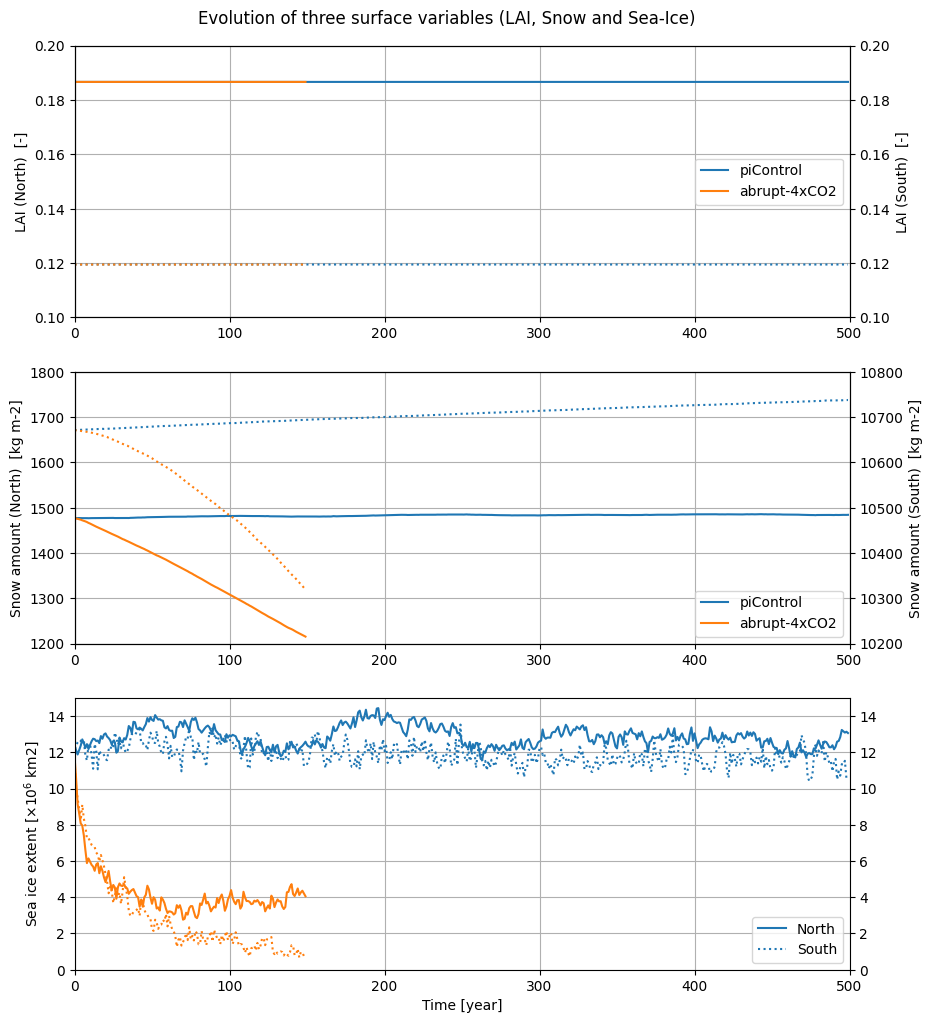

In [14]:
# plot temperature and energy anomalies
fig, axes = plt.subplots(3,1, figsize=(10, 12))


# piCtrl variables
lain     = (piCtrl['lain']).groupby('time.year').mean()
lais     = (piCtrl['lais']).groupby('time.year').mean()

snwn     = (piCtrl['snwn']).groupby('time.year').mean()
snws     = (piCtrl['snws']).groupby('time.year').mean()

siextn   = (piCtrl['siextentn']).groupby('time.year').mean()
siexts   = (piCtrl['siextents']).groupby('time.year').mean()

# abrupt variables
lain_a   = (abrupt['lain']).groupby('time.year').mean()
lais_a   = (abrupt['lais']).groupby('time.year').mean()

snwn_a   = (abrupt['snwn']).groupby('time.year').mean()
snws_a   = (abrupt['snws']).groupby('time.year').mean()

siextn_a = (abrupt['siextentn']).groupby('time.year').mean()
siexts_a = (abrupt['siextents']).groupby('time.year').mean()


# LAI
axes[0].plot( lain['year']-1850  , lain,   c='tab:blue',   ls='-' , label='piControl')
axes[0].plot( lain_a['year']-1850, lain_a, c='tab:orange', ls='-' , label='abrupt-4xCO2')
axes[0].legend(loc=5)

twinx_0 = axes[0].twinx()
twinx_0.plot( lais['year']-1850,   lais,   c='tab:blue',   ls=':')
twinx_0.plot( lais_a['year']-1850, lais_a, c='tab:orange', ls=':')

axes[0].set_ylim((0.1, 0.2))
twinx_0.set_ylim((0.1, 0.2))

axes[0].set_ylabel(r'LAI (North)  [-]')
twinx_0.set_ylabel(r'LAI (South)  [-]')


# Snow
axes[1].plot( snwn['year']-1850,   snwn,   c='tab:blue',   ls='-',  label='piControl')
axes[1].plot( snwn_a['year']-1850, snwn_a, c='tab:orange', ls='-' , label='abrupt-4xCO2')
axes[1].legend(loc=4)

twinx_1 = axes[1].twinx()
twinx_1.plot( snws['year']-1850,   snws,   c='tab:blue',   ls=':')
twinx_1.plot( snws_a['year']-1850, snws_a, c='tab:orange', ls=':')

axes[1].set_ylim((1200,  1800))
twinx_1.set_ylim((10200, 10800))

axes[1].set_ylabel(r'Snow amount (North)  [kg m-2]')
twinx_1.set_ylabel(r'Snow amount (South)  [kg m-2]')


# Sea ice
axes[2].plot( siextn['year']-1850, siextn, c='tab:blue', ls='-',  label='North')
axes[2].plot( siexts['year']-1850, siexts, c='tab:blue', ls=':', label='South')

axes[2].plot( siextn_a['year']-1850, siextn_a, c='tab:orange', ls='-')
axes[2].plot( siexts_a['year']-1850, siexts_a, c='tab:orange', ls=':')

axes[2].set_ylim((0, 15))
axes[2].set_ylabel(r'Sea ice extent [$\times 10^6$ km2]')

axes[2].yaxis.set_ticks_position('both')
axes[2].tick_params(labelright=True)
axes[2].legend()


for ax in axes:   
    ax.grid(True)    
    ax.set_xlim((0, 500))
    
    if ax == axes[-1]:
        ax.set_xlabel('Time [year]')
        

_ = fig.suptitle("Evolution of three surface variables (LAI, Snow and Sea-Ice) ", y=0.91)

<font color="blue">

Here we have plotted three different metrics showing surface changes during the two experiments. 
Each metric is decomposed into a northern and southern hemisphere value.

  - __Leaf area index__ (LAI) is a variable that represent the surface of vegetation per unit of area at the ground. Note that since vegetation occupies a 3D space, the LAI ratio can be greater than 1 (0 is a desert or urban area while 6 is highly dense forest such as tropical forests). In our simulations, the LAI metrics is constant and is not altered by the increase in CO$_2$ concentration (at least at the global scale). It is worth noting that the model used here does not represent the carbon cycle and the forest expansion is perhaps limited.   
    
    
  - As expected, most of the differences are found for the cryosphere (__snow amount__ and __sea_ice__). In particular, the sea ice exhibits a large retreat in both hemisphere in the forcing experiment. It is interesting to note that the sea-ice timeseries seems well correlated to the evolution of the upward shortwave radiation showing that it likely drives this change. One can note that, sea-ice extents are approximately similar in both hemisphere, but the northern ice shelf stabilize at a value twice than that of the southern. Conversely, snow amount is ten times greater in the southern hemispere (mostly due to the presence of the Antarctic) but exhibits the largest loss (around 350 kg.m-2). In the north, the loss is linear and reaches 280 kg.m-2 at the end of the _abrupt-4xcO2_ simulation.

Here we have highlighted the well known surface albedo feedback, which is mainly driven by changes in the cryosphere. However, it should be noted that the impact of the cryosphere in a changing climate is not limited to the albedo but includes air-sea interaction, ocean circulation alteration, water-cycle, etc..
    

</font>

#### Question 12

* _Using the figures and results you have plotted, propose a method to quantify the relative effect of a feedback._ 

__Help:__ we can assume a pre-industrial surface albedo $\alpha_0 \sim 0.3$

In [15]:
# Here, we focus on the surface albedo feedback

# First, compute the change in alpha
alpha_0     = 0.3
solar_in    = float(piCtrl['rsdt'].mean())           # or 1368/4 
piCtrl_SWup = float(piCtrl['rsut'].mean())
abrupt_SWup = float(abrupt['rsut'][-12*50:].mean())

alpha_f  = alpha_0 + (abrupt_SWup-piCtrl_SWup) / solar_in

# Then, compute the effective sensitivity parameter lambda
coeff_a  = - solar_in * (alpha_f-alpha_0) / ecs

print(r"New global surface albedo = {:.2f}".format(alpha_f))
print(r"Effective surface albedo sensitivity parameter = {:.2f} [W.m-2.K-1]".format(coeff_a))

New global surface albedo = 0.28
Effective surface albedo sensitivity parameter = 0.56 [W.m-2.K-1]


<font color="blue">

In the previous sections, we have shown :
  - the radiative budget is affected by the forcing in a similar way for all-sky and clear-sky conditions, illustrating a weak impact of clouds
  - the incoming solar radiation is constant though the simulation for each experiment
    
As a consequence, all surface changes that alter the upward radiative flux can be consider in a change in the global $\alpha$ parameter, so that:
    $$\Delta(\alpha S_0/4) = (\alpha_f - \alpha_0) S_0/4 = \Delta \mathrm{LW}_\text{up}$$

This give the new climate albedo $\alpha_f$ under CO$_2$ forcing:
    $$\alpha_f = \alpha_0 + \Delta \mathrm{LW}_\text{up} \times 4/S_0 \approx 0.28$$
    
To quantify the contribution of the albedo feedback to the climate sensitivity, one can compute the effective response relative to albedo:
    $$ \lambda_\alpha = \frac{\partial R}{\partial \alpha}\frac{\partial \alpha}{\partial T_s} = - S_0/4 \frac{\partial \alpha}{\partial T_s}$$
    
Or by linearized the previous equaition: $\lambda_\alpha = -S_0/4 \frac{\Delta \alpha}{\Delta T_s} \approx 0.56 \;\mathrm{W m}^{-2} \mathrm{K}^{-1}$
    
This value is larger but in the range of the expected value (0.35 $\pm$ 0.25 W.m-2.K-1) but calculation here have been made with short forcing simulation, and errors could arise from the choice in the global equilibrated variable (such as the ECS).
</font>

#### Going further (optional)

In the previous sections, we have relate the Earth energy balance with physical and climate variables. 
However, there are still topics to explore if wanted. Among other:

* _For now, we have mainly explained the variation in the shortwave upward flux. What are the mechanisms that drive the upward longwave changes ?._
* _We have seen that the increase in surface temperature can drive a surface albedo feedback. Howeve, we have only made calculation using global integrated value. Finer analysing is often required to spatialize and understand where the changes occur._
* _There are plenty of variables that are simulated by general circulation models, you can ask fo any ideas or wishes that is able to satisfy your curiosity !_

## 4. Conclusion and discussion

TODO: mettre plusieurs modèles CMIP pour calculer l'incertitude sur ECS + lambda !

We conclude the notebook by using output from another CMIP6 model. The following lines, will load global overaged monthly outputs from the ACCESS-CM2 climate model [(Bi et al., 2020)](https://connectsci.au/es/article/70/1/225/73456/Configuration-and-spin-up-of-ACCESS-CM2-the-new)) developped by the Australian climate modelling community:   


```python
# initialize empty dict to store variables
piCtrl_cm2 = dict()
abrupt_cm2 = dict()

# load netCDF (.nc) files using xarray
for f in os.listdir("../data/CMIP6"):
    var   = f.split('_')[0]
    model = f.split('_')[2]
    expe  = f.split('_')[3]
    
    # select only ACCESS-CM2 model
    if model == 'ACCESS-CM2':
        ds = xr.load_dataset(os.path.join("../data/CMIP6", f), use_cftime=True)
        
        if expe == 'piControl':
            piCtrl_cm2[var]      = ds[list(ds.variables)[-1]]
            piCtrl_cm2[var].name = var
        elif expe == 'abrupt-4xCO2':
            abrupt_cm2[var]      = ds[list(ds.variables)[-1]]
            abrupt_cm2[var].name = var
            
print("Variables loaded in piCtrl_cm2: \n", list(piCtrl_cm2.keys()))
print("")
print("Variables loaded in abrupt_cm2: \n", list(abrupt_cm2.keys())) 
```

#### Question 13

* _Compare some of the results you have obtained from CNRM-CM6-1 by computing similar metrics with the new experiments._
* _Comment on the similarities and differences. What about uncertainty of your results ?_ 

In [43]:
# initialize empty dict to store variables
piCtrl_cm2 = dict()
abrupt_cm2 = dict()

# load netCDF (.nc) files using xarray
for f in os.listdir("../data/CMIP6"):
    var   = f.split('_')[0]
    model = f.split('_')[2]
    expe  = f.split('_')[3]

    # select only ACCESS-CM2 model
    if model == 'ACCESS-CM2':
        ds = xr.load_dataset(os.path.join("../data/CMIP6", f), use_cftime=True)

        if expe == 'piControl':
            piCtrl_cm2[var]      = ds[list(ds.variables)[-1]]
            piCtrl_cm2[var].name = var
        elif expe == 'abrupt-4xCO2':
            abrupt_cm2[var]      = ds[list(ds.variables)[-1]]
            abrupt_cm2[var].name = var

print("Variables loaded in piCtrl_cm2: \n", list(piCtrl_cm2.keys()))
print("")
print("Variables loaded in abrupt_cm2: \n", list(abrupt_cm2.keys())) 

Variables loaded in piCtrl_cm2: 
 ['rsdt', 'ts', 'rsutcs', 'rsut', 'rlut', 'rlutcs']

Variables loaded in abrupt_cm2: 
 ['rlutcs', 'rsdt', 'rsut', 'rsutcs', 'ts', 'rlut']


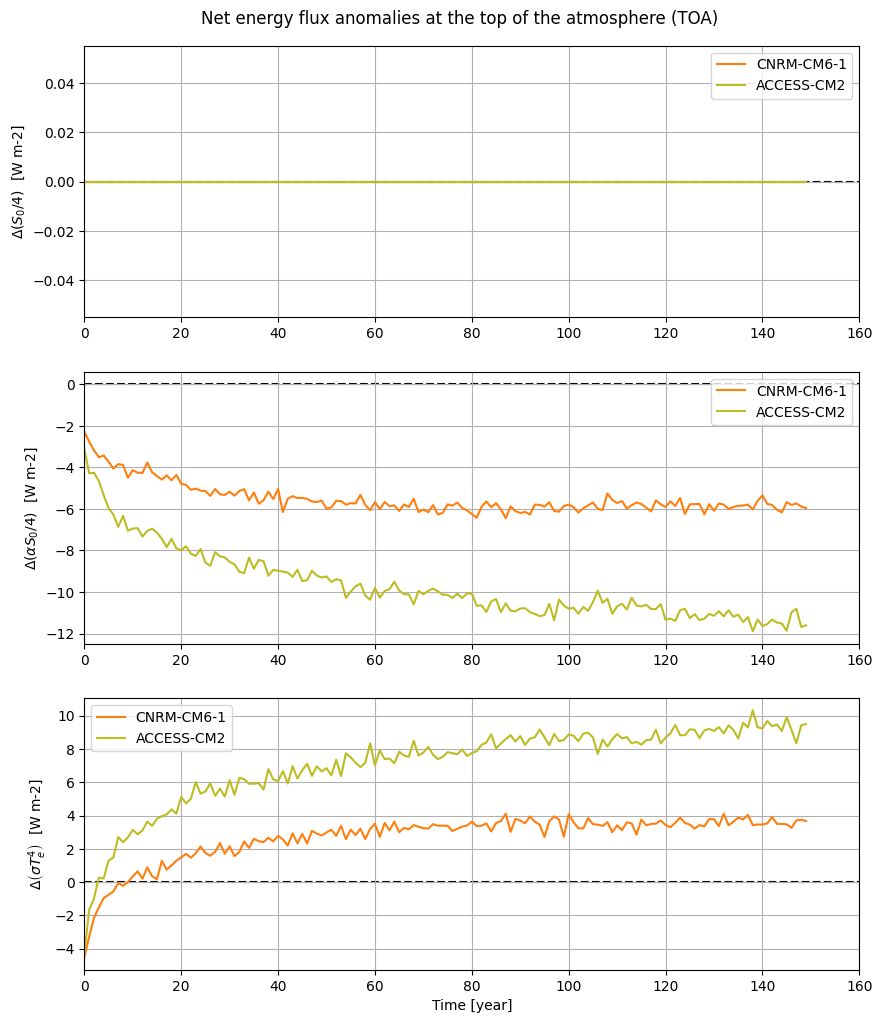

In [46]:
# plot temperature and energy anomalies
fig, axes = plt.subplots(3,1, figsize=(10, 12))


# dR (CNRM_CM6-1)
dRLUT     = (abrupt['rlut'] - piCtrl['rlut']).groupby('time.year').mean()
dRSUT     = (abrupt['rsut'] - piCtrl['rsut']).groupby('time.year').mean()
dRSDT     = (abrupt['rsdt'] - piCtrl['rsdt']).groupby('time.year').mean()

axes[0].plot( np.arange(len(dRSDT['year'])), dRSDT, c='tab:orange', label='CNRM-CM6-1')
axes[1].plot( np.arange(len(dRSUT['year'])), dRSUT, c='tab:orange', label='CNRM-CM6-1')
axes[2].plot( np.arange(len(dRLUT['year'])), dRLUT, c='tab:orange', label='CNRM-CM6-1')


# dR (ACCESS-CM2)
dRLUT     = (abrupt_cm2['rlut'] - piCtrl_cm2['rlut']).groupby('time.year').mean()
dRSUT     = (abrupt_cm2['rsut'] - piCtrl_cm2['rsut']).groupby('time.year').mean()
dRSDT     = (abrupt_cm2['rsdt'] - piCtrl_cm2['rsdt']).groupby('time.year').mean()

axes[0].plot( np.arange(len(dRSDT['year'])), dRSDT, c='tab:olive', label='ACCESS-CM2')
axes[1].plot( np.arange(len(dRSUT['year'])), dRSUT, c='tab:olive', label='ACCESS-CM2')
axes[2].plot( np.arange(len(dRLUT['year'])), dRLUT, c='tab:olive', label='ACCESS-CM2')


# Axes
axes[0].set_ylabel(r'$\Delta \left(S_0/4\right)$  [W m-2]')
axes[1].set_ylabel(r'$\Delta \left(\alpha S_0/4\right)$  [W m-2]')
axes[2].set_ylabel(r'$\Delta \left(\sigma T_e^4\right)$  [W m-2]')

for ax in axes:
    ax.hlines(0,0,160, color="k", ls="--", alpha=1, zorder=-10)
    ax.legend()
    ax.grid(True)
    ax.set_xlim((0, 160))
    
    if ax == axes[-1]:
        ax.set_xlabel('Time [year]')

_ = fig.suptitle("Net energy flux anomalies at the top of the atmosphere (TOA)", y=0.91)

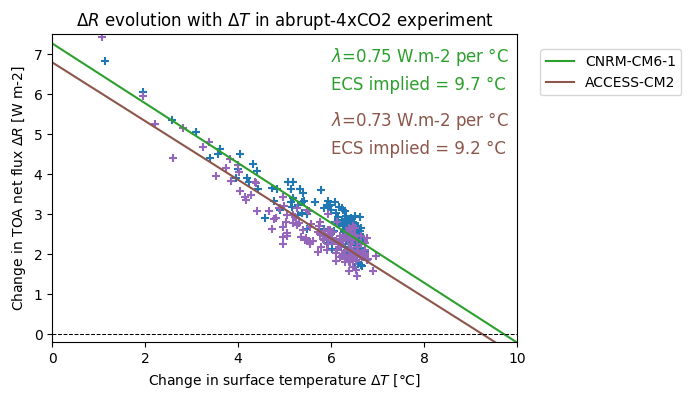

In [56]:
# plot
fig, ax = plt.subplots(1,1, figsize=(6, 4))


# CNRM-CM6-1: compute and plot linear trend + ECS
ax.scatter( dT, dR, marker='+', c='tab:blue')

x         = np.vstack([dT, np.ones(len(dT))]).T
coeff, R0 = np.linalg.lstsq(x, dR, rcond=-1)[0]

ecs       = -R0 / coeff  # dT = -dR/lambda

# -- plot trend
ax.plot( np.linspace(0, 10, 100), coeff * np.linspace(0, 10, 100) + R0, ls='-', c='tab:green', label='CNRM-CM6-1')
ax.text(6, 6.8,   r"$\lambda$={:.2f} W.m-2 per °C".format(-coeff), fontsize=12,  c='tab:green')
ax.text(6, 6.1, r"ECS implied = {:.1f} °C".format(ecs),           fontsize=12,  c='tab:green')


# ACCESS-CM2: compute and plot linear trend + ECS
dR_piCtrl_cm2 = (piCtrl_cm2['rsdt'] - piCtrl_cm2['rsut'] - piCtrl_cm2['rlut']).groupby('time.year').mean()
dR_abrupt_cm2 = (abrupt_cm2['rsdt'] - abrupt_cm2['rsut'] - abrupt_cm2['rlut']).groupby('time.year').mean()

dT_access    = (abrupt_cm2['ts'] - piCtrl_cm2['ts']).groupby('time.year').mean()
dR_access    =  dR_abrupt_cm2    - dR_piCtrl_cm2

# -- plot scatter points
ax.scatter( dT_access, dR_access, marker='+', c='tab:purple')

x            = np.vstack([dT_access, np.ones(len(dT_access))]).T
coef_cm2, R0 = np.linalg.lstsq(x, dR_access, rcond=-1)[0]

ecs_cm2      = -R0 / coef_cm2  # dT = -dR/lambda

# -- plot trend
ax.plot( np.linspace(0, 10, 100), coefa * np.linspace(0, 10, 100) + R0, ls='-', c='tab:brown', label='ACCESS-CM2')
ax.text(6, 5.2,   r"$\lambda$={:.2f} W.m-2 per °C".format(-coef_cm2), fontsize=12,  c='tab:brown')
ax.text(6, 4.5, r"ECS implied = {:.1f} °C".format(ecs_cm2),     fontsize=12,  c='tab:brown')

# plot y=0 line
ax.plot( [0, 10], [0, 0], ls='--', lw=0.75, c='k')


# axe properties
ax.set_xlim((0, 10))
ax.set_ylim((-0.2, 7.5))
ax.set_xlabel(r'Change in surface temperature $\Delta T$ [°C]')
ax.set_ylabel(r'Change in TOA net flux $\Delta R$ [W m-2]')

ax.legend(loc=(1.05,0.8))

_ = ax.set_title(r"$\Delta R$ evolution with $\Delta T$ in abrupt-4xCO2 experiment")

<font color="blue">

Here, we can let the student do their own analysis..
    
</font>

#### Question 14

* _Propose a summary and conclusion of the notebook._ 

<font color="blue">

Conclusion should include:
    
  - short presentation of the lecture (simulations used here, for what purposes, etc.)
  - method and main results
  - discussion (uncertainty, limitations, how to reduce these limitations, etc.)
  - conclusion (e.g. what have they learned during the lecture)

</font>